# Example 4.1: MLP Architecture and Forward Pass
**Chapter 4 · Neural Networks for Mechanism Design**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

## Statement
Build a Multilayer Perceptron (MLP) with an architecture of **3 inputs → 8 hidden neurons (ReLU) → 1 linear output** using Xavier initialization. Implement the forward pass using only `numpy` and evaluate the untrained model on three samples of four-bar mechanisms.

**Objective:** Understand how information flows through an MLP network and how many trainable parameters each layer has.

In [1]:
# ── Imports─────────────────────────────────────────────────────────
from numpy import *
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family': 'serif', 'font.size': 12})

In [5]:
random.seed(0)

    # Architecture: 3 inputs -> 8 hidden (ReLU) -> 1 output (linear)
N_IN, N_HID, N_OUT = 3, 8, 1

    # Xavier Initialization
W1 = random.randn(N_IN, N_HID) * sqrt(2.0 / N_IN)
b1 = zeros(N_HID)
W2 = random.randn(N_HID, N_OUT) * sqrt(2.0 / N_HID)
b2 = zeros(N_OUT)

def relu(x):
    return maximum(0, x)

def forward(X, W1, b1, W2, b2):
    H = relu(X @ W1 + b1)   # hidden layer
    Y = H @ W2 + b2          # output layer (linear)
    return Y.ravel()

    # Example data (normalized: lengths / 120)
    X_ejemplo = array([[50, 100, 75],
                       [40,  80, 60],
                       [60, 110, 85]]) / 120.0

    predicciones = forward(X_ejemplo, W1, b1, W2, b2)

    print('MLP Parameters:')
    print(f'  W1: {W1.shape} -> {W1.size} weights')
    print(f'  W2: {W2.shape} -> {W2.size} weights')
    print(f'  Total parameters: {W1.size + b1.size + W2.size + b2.size}')
    print()
    print('Predictions (estimated Hausdorff error, untrained):')
    for i, (x, y) in enumerate(zip(X_ejemplo, predicciones)):
        print(f'  Sample {i+1}: a={x[0]*120:.0f}, b={x[1]*120:.0f}, '
              f'c={x[2]*120:.0f} -> y_hat = {y:.4f}')


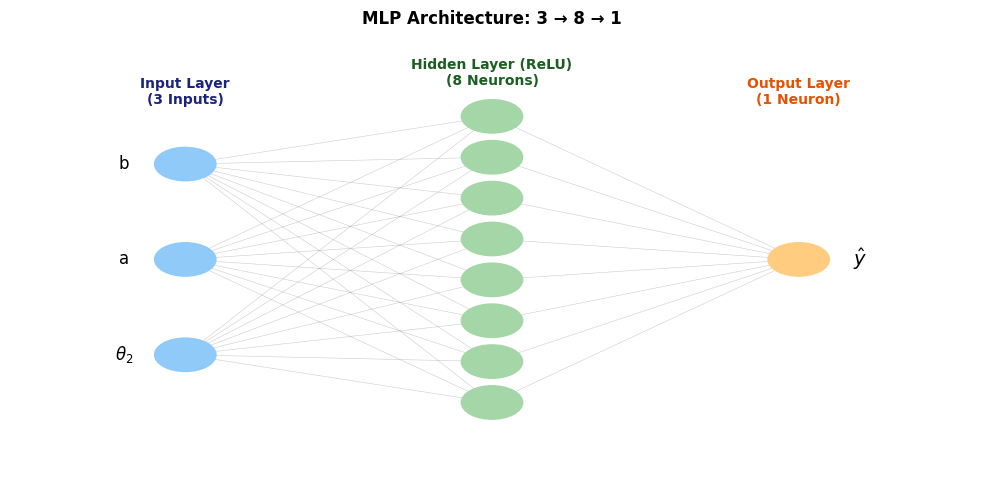

In [6]:
import os
import glob
from numpy import linspace
import matplotlib.pyplot as plt

# ─── Springer Editorial Font & Quality Config ───
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['DejaVu Sans', 'Arial', 'Helvetica']})

# ─── Automated Filename System ───
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "Figura_4.1_mlp_forward_architecture"
except Exception:
    notebook_name = "Figura_4.1_mlp_forward_architecture"

# ─── Figure Generation ───
fig, ax = plt.subplots(figsize=(10, 5))
ax.set_xlim(-0.5, 10.5)  # Extended margins to prevent labels from clipping
ax.set_ylim(-0.5, 8.5)
ax.axis('off')

# Input layer nodes (3)
in_y = [2, 4, 6]
hid_y = linspace(1, 7, 8)
out_y = [4]

in_x, hid_x, out_x = 1.5, 5.0, 8.5

# Connections entry->hidden
for iy in in_y:
    for hy in hid_y:
        ax.plot([in_x, hid_x], [iy, hy], 'gray', lw=0.4, alpha=0.4)
# Hidden connections->output
for hy in hid_y:
    ax.plot([hid_x, out_x], [hy, out_y[0]], 'gray', lw=0.4, alpha=0.4)

# Nodes
for iy in in_y:
    ax.add_patch(plt.Circle((in_x, iy), 0.35, color='#90CAF9', zorder=3))
for hy in hid_y:
    ax.add_patch(plt.Circle((hid_x, hy), 0.35, color='#A5D6A7', zorder=3))
for oy in out_y:
    ax.add_patch(plt.Circle((out_x, oy), 0.35, color='#FFCC80', zorder=3))

# Layer labels (Slightly adjusted coordinates to prevent overlapping with title)
ax.text(in_x,  7.2, 'Input Layer\n(3 Inputs)', ha='center', va='bottom', fontsize=10, fontweight='bold', color='#1A237E')
ax.text(hid_x, 7.6, 'Hidden Layer (ReLU)\n(8 Neurons)', ha='center', va='bottom', fontsize=10, fontweight='bold', color='#1B5E20')
ax.text(out_x, 7.2, 'Output Layer\n(1 Neuron)', ha='center', va='bottom', fontsize=10, fontweight='bold', color='#E65100')

# Post tags
labels_in = [r'$\theta_2$', 'a', 'b']
for iy, lab in zip(in_y, labels_in):
    ax.text(in_x - 0.7, iy, lab, ha='center', va='center', fontsize=12)

ax.text(out_x + 0.7, out_y[0], r'$\hat{y}$', ha='center', va='center', fontsize=14)

# Main Title
ax.set_title('MLP Architecture: 3 → 8 → 1', fontsize=12, fontweight='bold', pad=15)

# ─── Dual Export ───
plt.tight_layout()
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()